
# STRATUM — Baseline Regression and Evaluation Framework

## Phase 3 — Step 3.1

### Objective

Establish reproducible baseline regression performance
for semiconductor virtual metrology before developing
more advanced machine-learning models.

### Primary Prediction Target

mean_thickness

### Baseline Models

1. Global mean regression.
2. Global median regression.
3. Equipment-specific mean regression.

### Evaluation Metrics

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R2)
- Mean Absolute Percentage Error (MAPE)
- Mean Prediction Bias

### Evaluation Protocol

- Reuse the chronological and lot-aware partitions
  established during Phase 2.
- Fit baseline models using training data only.
- Compare models using validation data.
- Reserve final test records for Phase 3.8.
- Do not use post-process metrology outputs as inputs.
- Use MAE as the primary model-comparison metric.

### Purpose

Determine whether more advanced virtual metrology
models provide measurable improvements over
simple historical prediction strategies.

In [1]:

# STEP 3.1.5 - Import libraries and modules

from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor

sns.set_theme(style="whitegrid")

# Locate the STRATUM project root
current_dir = Path.cwd()

if (current_dir / "ml" / "evaluation.py").exists():
    project_root = current_dir

elif (
    current_dir.parent / "ml" / "evaluation.py"
).exists():
    project_root = current_dir.parent

else:
    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.data_split import chronological_lot_split

from ml.preprocessing import (
    get_feature_columns,
)

from ml.evaluation import (
    evaluate_regression,
    calculate_mae_improvement,
)

from ml.baselines import EquipmentMeanRegressor

print("STRATUM - Baseline Regression")
print("All modules imported successfully!")

STRATUM - Baseline Regression
All modules imported successfully!


## 1. Dataset and Split Reproducibility

Verify the original dataset fingerprint and reproduce
the chronological and lot-aware data partitions
defined during Phase 2.

In [2]:

# STEP 3.1.6 - Verify dataset fingerprint

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest_path = (
    project_root
    / "docs"
    / "split_manifest.json"
)

with open(
    manifest_path,
    "r",
    encoding="utf-8",
) as file:
    manifest = json.load(file)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert current_sha256 == manifest["dataset_sha256"], (
    "Dataset fingerprint does not match the manifest."
)

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

assert df.shape == (5208, 178)

print("Dataset fingerprint: VERIFIED")
print("Dataset shape:", df.shape)

Dataset fingerprint: VERIFIED
Dataset shape: (5208, 178)


In [3]:

# Reproduce the chronological partitions

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,
        test_fraction=manifest["test_fraction"],
        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == manifest["split_summary"], (
    "Current split differs from the saved manifest."
)

apc_features, feature_columns = (
    get_feature_columns(df)
)

assert (
    apc_features == manifest["numeric_apc_features"]
), "APC feature schema has changed."

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Reserved test records:", len(test_df))

print("\nDataset split reproducibility: VERIFIED")

Training records: 3331
Validation records: 834
Reserved test records: 1042

Dataset split reproducibility: VERIFIED


## 2. Input and Target Preparation

Prepare training and validation inputs for
mean film thickness prediction.

The test targets remain reserved for final evaluation.

In [4]:

# STEP 3.1.7 - Prepare model inputs

TARGET = "mean_thickness"

X_train = train_df[feature_columns].copy()
X_val = val_df[feature_columns].copy()

y_train = train_df[TARGET].copy()
y_val = val_df[TARGET].copy()

assert TARGET not in X_train.columns
assert TARGET not in X_val.columns

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

assert np.isfinite(y_train).all()
assert np.isfinite(y_val).all()

print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)

print("\nTraining target statistics:")
display(y_train.describe().round(4))

print("\nTarget preparation successful!")

Training input shape: (3331, 111)
Validation input shape: (834, 111)

Training target statistics:


count    3331.0000
mean      152.3383
std         2.4859
min       141.9621
25%       150.8776
50%       152.4186
75%       153.9520
max       163.6418
Name: mean_thickness, dtype: float64


Target preparation successful!


## 3. Global Mean Baseline

Train a constant regression model using the
mean thickness of the training partition.

Evaluate predictions using validation records only.

In [5]:

# STEP 3.1.8 - Mean baseline

X_train_dummy = np.zeros(
    (len(y_train), 1)
)

X_val_dummy = np.zeros(
    (len(y_val), 1)
)

mean_baseline = DummyRegressor(
    strategy="mean"
)

mean_baseline.fit(
    X_train_dummy,
    y_train
)

mean_predictions = mean_baseline.predict(
    X_val_dummy
)

mean_metrics = evaluate_regression(
    y_val,
    mean_predictions
)

print(
    "Constant thickness prediction:",
    round(float(mean_predictions[0]), 6)
)

display(
    pd.DataFrame(
        [mean_metrics],
        index=["Global Mean"]
    ).round(6)
)

Constant thickness prediction: 152.338289


,MAE,RMSE,R2,MAPE (%),Bias
Global Mean,2.058493,2.537936,-0.079733,1.363357,0.68967


## 4. Global Median Baseline

Train a constant regression model using the median
thickness of the training partition.

Compare its validation performance with the
global mean baseline.

In [6]:

# STEP 3.1.9 - Median baseline

median_baseline = DummyRegressor(
    strategy="median"
)

median_baseline.fit(
    X_train_dummy,
    y_train
)

median_predictions = median_baseline.predict(
    X_val_dummy
)

median_metrics = evaluate_regression(
    y_val,
    median_predictions
)

print(
    "Constant thickness prediction:",
    round(float(median_predictions[0]), 6)
)

display(
    pd.DataFrame(
        [median_metrics],
        index=["Global Median"]
    ).round(6)
)

Constant thickness prediction: 152.418591


,MAE,RMSE,R2,MAPE (%),Bias
Global Median,2.075573,2.560924,-0.099381,1.375287,0.769972


## 5. Equipment-Specific Mean Baseline

Learn average thickness values for each equipment
identifier using training records only.

Predict validation thickness using the corresponding
equipment-specific historical average.

Unknown equipment categories fall back to the global
training-set mean.

In [7]:

# STEP 3.1.10 - Equipment mean baseline

equipment_baseline = EquipmentMeanRegressor(
    equipment_column="equipment"
)

equipment_baseline.fit(
    X_train[["equipment"]],
    y_train
)

equipment_predictions = equipment_baseline.predict(
    X_val[["equipment"]]
)

equipment_metrics = evaluate_regression(
    y_val,
    equipment_predictions
)

print(
    "Equipment averages learned:",
    len(equipment_baseline.equipment_means_)
)

print(
    "Global fallback prediction:",
    round(equipment_baseline.global_mean_, 6)
)

display(
    pd.DataFrame(
        [equipment_metrics],
        index=["Equipment Mean"]
    ).round(6)
)

Equipment averages learned: 16
Global fallback prediction: 152.338289


,MAE,RMSE,R2,MAPE (%),Bias
Equipment Mean,1.995479,2.44438,-0.001596,1.320842,0.664447


In [8]:

# Inspect equipment-specific training averages

equipment_averages = pd.Series(
    equipment_baseline.equipment_means_,
    name="Training Mean Thickness"
)

display(
    equipment_averages
    .sort_values()
    .round(4)
    .to_frame()
)

,Training Mean Thickness
equipment_12,150.1315
equipment_4,150.9607
equipment_9,151.9217
equipment_8,152.0304
equipment_13,152.2275
equipment_14,152.2376
equipment_15,152.4647
equipment_7,152.5175
equipment_2,152.5177
equipment_1,152.6003


In [9]:

# Test fallback behaviour

unknown_equipment = pd.DataFrame({
    "equipment": ["equipment_unseen_demo"]
})

fallback_prediction = (
    equipment_baseline.predict(
        unknown_equipment
    )[0]
)

assert np.isclose(
    fallback_prediction,
    equipment_baseline.global_mean_
)

print("Unknown equipment fallback: PASSED")
print("Fallback prediction:", fallback_prediction)

Unknown equipment fallback: PASSED
Fallback prediction: 152.3382893627239


## 6. Baseline Model Comparison

Compare all three regression baselines on
the same chronological validation partition.

Use MAE as the primary comparison metric.

RMSE, R2, MAPE and prediction bias provide
additional performance information.

In [10]:

# STEP 3.1.11 - Compare baseline performance

baseline_results = pd.DataFrame([
    {
        "Model": "Global Mean",
        **mean_metrics
    },
    {
        "Model": "Global Median",
        **median_metrics
    },
    {
        "Model": "Equipment Mean",
        **equipment_metrics
    },
])

baseline_results = (
    baseline_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

best_baseline = baseline_results.iloc[0]

print("Baseline validation results:")
display(baseline_results.round(6))

print("\nBest baseline according to MAE:")
print(best_baseline["Model"])

print(
    "Best baseline MAE:",
    round(best_baseline["MAE"], 6)
)

Baseline validation results:


,Model,MAE,RMSE,R2,MAPE (%),Bias
0,Equipment Mean,1.995479,2.444380,-0.001596,1.320842,0.664447
1,Global Mean,2.058493,2.537936,-0.079733,1.363357,0.689670
2,Global Median,2.075573,2.560924,-0.099381,1.375287,0.769972



Best baseline according to MAE:
Equipment Mean
Best baseline MAE: 1.995479


## 7. Baseline Performance Visualisation

Visualise regression error across the baseline models.

Examine actual versus predicted values and
the distribution of prediction residuals.

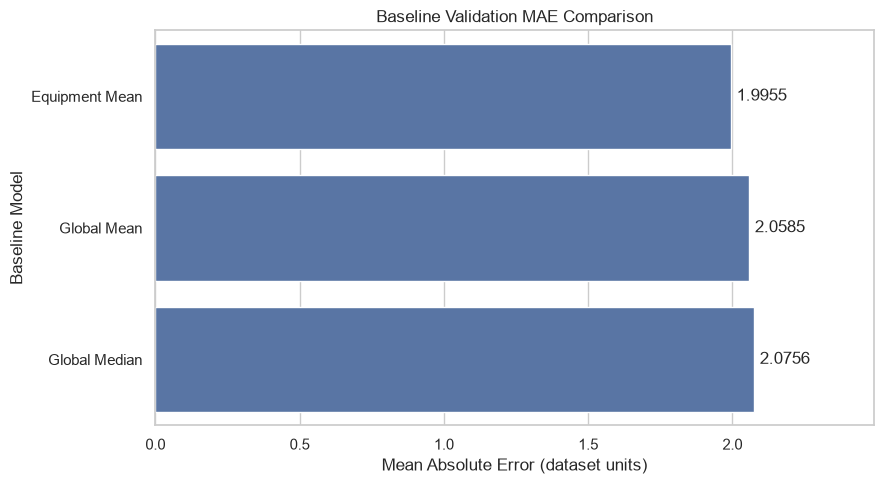

In [11]:

# STEP 3.1.12A - MAE comparison

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=baseline_results,
    x="MAE",
    y="Model"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.4f",
    padding=4
)

plt.title("Baseline Validation MAE Comparison")
plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("Baseline Model")

plt.xlim(
    0,
    baseline_results["MAE"].max() * 1.2
)

plt.tight_layout()
plt.show()

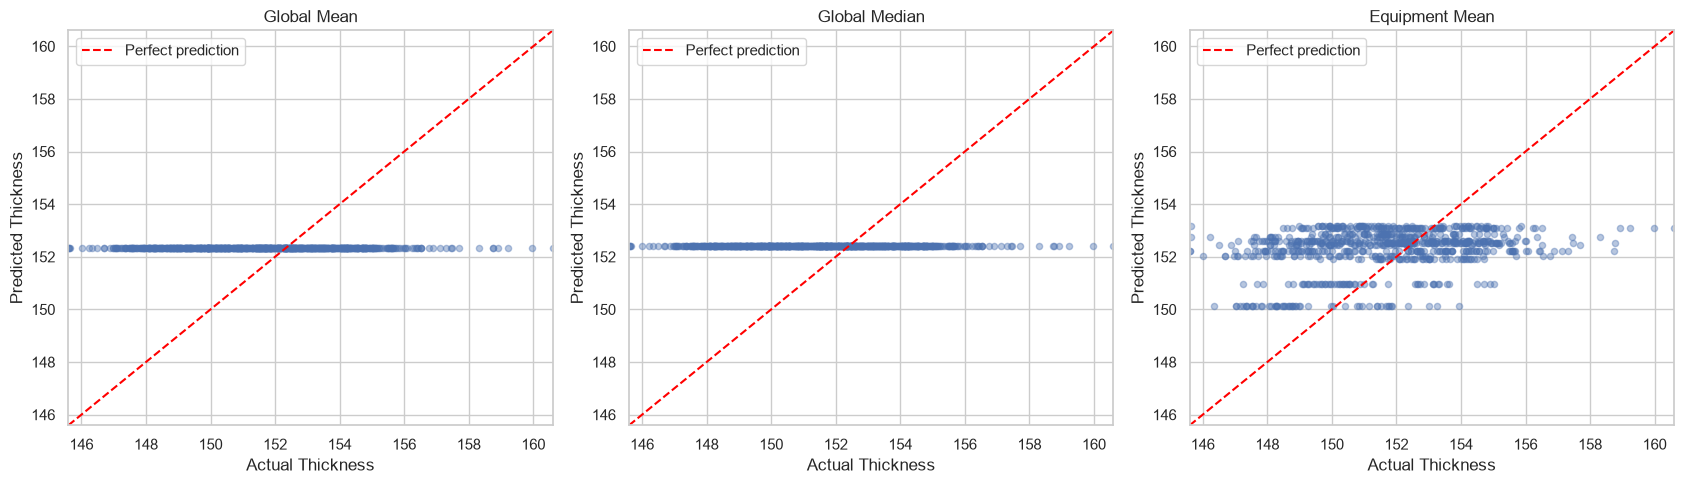

In [12]:

# STEP 3.1.12B - Actual vs predicted thickness

prediction_sets = {
    "Global Mean": mean_predictions,
    "Global Median": median_predictions,
    "Equipment Mean": equipment_predictions,
}

all_predictions = np.concatenate(
    list(prediction_sets.values())
)

lower = min(
    y_val.min(),
    all_predictions.min()
)

upper = max(
    y_val.max(),
    all_predictions.max()
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, (name, predictions) in zip(
    axes,
    prediction_sets.items()
):
    ax.scatter(
        y_val,
        predictions,
        alpha=0.4,
        s=20
    )

    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        color="red",
        label="Perfect prediction"
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)

    ax.set_title(name)
    ax.set_xlabel("Actual Thickness")
    ax.set_ylabel("Predicted Thickness")
    ax.legend()

plt.tight_layout()
plt.show()

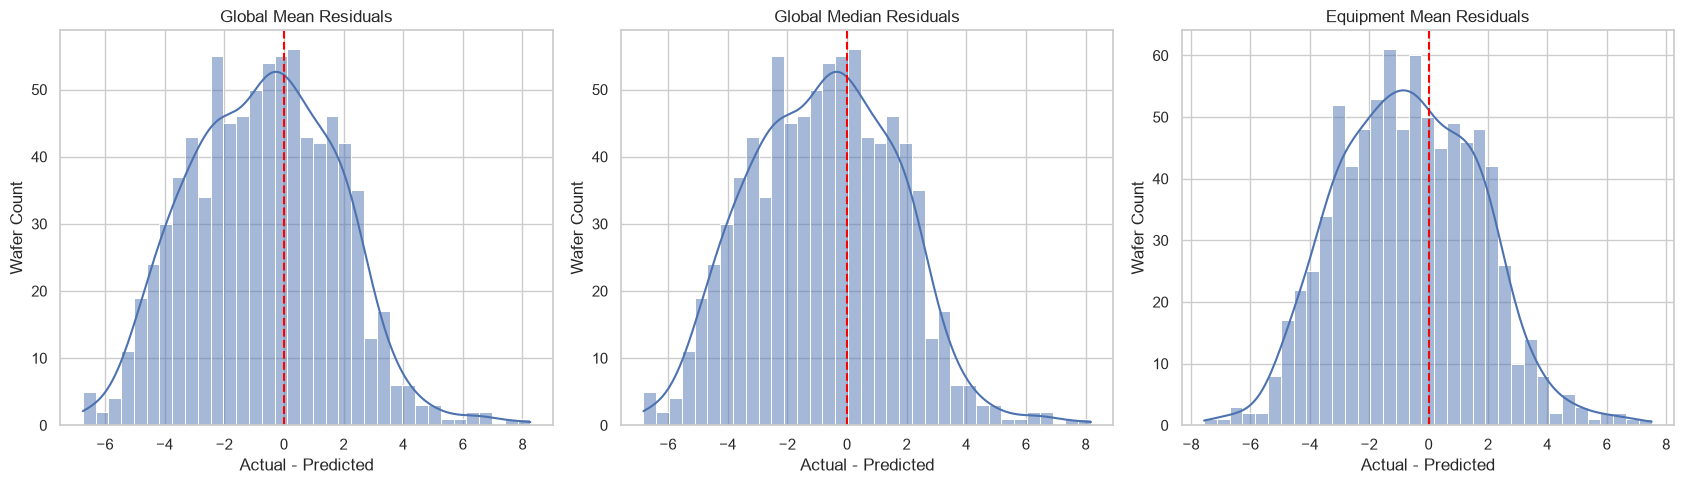

In [13]:

# STEP 3.1.12C - Residual distributions

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, (name, predictions) in zip(
    axes,
    prediction_sets.items()
):
    residuals = (
        y_val.to_numpy() - predictions
    )

    sns.histplot(
        residuals,
        bins=35,
        kde=True,
        ax=ax
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(f"{name} Residuals")
    ax.set_xlabel("Actual - Predicted")
    ax.set_ylabel("Wafer Count")

plt.tight_layout()
plt.show()

## 8. Baseline Improvement Analysis

Quantify the percentage reduction in validation MAE
relative to the global mean prediction strategy.

In [14]:

# STEP 3.1.13 - Baseline improvement

global_mean_mae = mean_metrics["MAE"]

baseline_results["MAE Improvement (%)"] = (
    baseline_results["MAE"]
    .apply(
        lambda mae: calculate_mae_improvement(
            global_mean_mae,
            mae
        )
    )
)

display(baseline_results.round(6))

,Model,MAE,RMSE,R2,MAPE (%),Bias,MAE Improvement (%)
0,Equipment Mean,1.995479,2.444380,-0.001596,1.320842,0.664447,3.061179
1,Global Mean,2.058493,2.537936,-0.079733,1.363357,0.689670,0.000000
2,Global Median,2.075573,2.560924,-0.099381,1.375287,0.769972,-0.829746


## 9. Experiment Result Preservation

Save baseline validation metrics and experiment
metadata for future model comparison.

No individual wafer measurements or test predictions
are exported.

In [15]:

# STEP 3.1.14 - Save baseline experiment results

results_dir = (
    project_root / "ml" / "results"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

results_path = (
    results_dir / "thickness_baselines.json"
)

experiment_results = {
    "project": "STRATUM",
    "experiment": "thickness_baseline_regression",
    "target": TARGET,
    "dataset_sha256": current_sha256,
    "evaluation_partition": "validation",
    "training_records": len(train_df),
    "validation_records": len(val_df),
    "primary_metric": "MAE",
    "best_baseline": str(best_baseline["Model"]),
    "best_baseline_mae": float(
        best_baseline["MAE"]
    ),
    "results": baseline_results.to_dict(
        orient="records"
    ),
}

with open(
    results_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        experiment_results,
        file,
        indent=4,
        allow_nan=False,
    )

print("Baseline results saved successfully.")
print("ml/results/thickness_baselines.json")

Baseline results saved successfully.
ml/results/thickness_baselines.json


## 10. Evaluation Framework Verification

Verify regression metric calculations using
a small synthetic example with known results.

This check is independent of the Infineon dataset.

In [16]:

# STEP 3.1.15 - Verify evaluation calculations

actual_example = np.array([
    100.0, 150.0, 200.0
])

predicted_example = np.array([
    90.0, 150.0, 210.0
])

example_metrics = evaluate_regression(
    actual_example,
    predicted_example
)

assert np.isclose(
    example_metrics["MAE"],
    20 / 3
)

assert np.isclose(
    example_metrics["RMSE"],
    np.sqrt(200 / 3)
)

assert np.isclose(
    example_metrics["R2"],
    0.96
)

assert np.isclose(
    example_metrics["MAPE (%)"],
    5.0
)

assert np.isclose(
    example_metrics["Bias"],
    0.0
)

assert np.isclose(
    calculate_mae_improvement(2.5, 2.0),
    20.0
)

display(
    pd.DataFrame(
        [example_metrics]
    ).round(6)
)

print("Evaluation framework verification: PASSED")

,MAE,RMSE,R2,MAPE (%),Bias
0,6.666667,8.164966,0.96,5.0,0.0


Evaluation framework verification: PASSED



## 11. Findings and Interpretation

### Evaluation Framework

Implemented a reusable regression evaluation module
providing MAE, RMSE, R2, MAPE and prediction bias.

Verified the metric calculations using synthetic
observations with known expected results.

### Dataset Reproducibility

- Verified the original dataset SHA-256 fingerprint.
- Reproduced the chronological and lot-aware partitions.
- Confirmed 3,331 training records.
- Confirmed 834 validation records.
- Reserved 1,042 test records for final evaluation.
- Verified the expected APC feature schema.

### Baseline Models

Evaluated three prediction strategies:

1. Global training mean.
2. Global training median.
3. Equipment-specific training mean.

All baseline parameters were learned using
training records only.

### Evaluation Results

Insert the actual validation metrics for all three
baseline models after executing the notebook.

Record the best baseline according to MAE and
its improvement relative to the global mean.

### Engineering Interpretation

The baseline models establish minimum predictive
performance benchmarks for semiconductor virtual
metrology.

The equipment-specific baseline investigates whether
historical equipment averages alone provide useful
predictive information.

Advanced machine-learning models must demonstrate
measurable improvement over these simple strategies
to justify their additional complexity.

### Limitations

- Baseline models do not learn relationships
  between APC sensor measurements and thickness.
- Historical averages may be affected by temporal shifts.
- Validation performance is not final test performance.
- Generalisation to entirely new equipment has
  not been established.

### Conclusion

STRATUM now has a reproducible regression evaluation
framework and documented baseline performance.

The next stage will investigate sensor-based linear
and regularised regression models.